# 00 · Data preparation — Victoria drug offences (RQ1)

**RQ1:** *How do drug type and offence type (supply vs use) vary across Victoria's LGAs, and how did this geography change from 2017 to 2026?*

This notebook use the CSA workbooks and ABS boundaries  into clean, analysis-ready files in `data/processed/`.
Notebooks 01–03 read only from there.

| Source | File (`data/raw/`, `data/boundaries/`) | Grain | Used for |
|---|---|---|---|
| CSA Recorded Offences (**main**) | `Data_Tables_LGA_Recorded_Offences_Year_Ending_June_2026.xlsx` | LGA / suburb × offence × year, drug type by LGA | All analysis |
| CSA Criminal Incidents (LGA) | `Data_Tables_LGA_Criminal_Incidents_Year_Ending_June_2026.xlsx` | LGA × principal offence × year | Incidents vs offences comparison |
| CSA Criminal Incidents (statewide) | `Data_Tables_Criminal_Incidents_Visualisation_Year_Ending_June_2026.xlsx` | State × principal offence × location type / charge status | Where drug incidents happen, how they resolve |
| ABS ASGS Ed. 3 LGA 2024 | `LGA_2024/LGA_2024_AUST_GDA2020.shp` | LGA polygons | Maps, spatial weights |

In [2]:
import urllib.request
import zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW = ROOT / 'data' / 'raw'
BND = ROOT / 'data' / 'boundaries'
OUT = ROOT / 'data' / 'processed'
OUT.mkdir(exist_ok=True)

OFFENCES_XLSX = RAW / 'Data_Tables_LGA_Recorded_Offences_Year_Ending_June_2026.xlsx'
INCIDENTS_XLSX = RAW / 'Data_Tables_LGA_Criminal_Incidents_Year_Ending_June_2026.xlsx'
STATE_XLSX = RAW / 'Data_Tables_Criminal_Incidents_Visualisation_Year_Ending_June_2026.xlsx'

LGA_URL = ('https://www.abs.gov.au/statistics/standards/australian-statistical-geography-standard-asgs-edition-3/'
           'jul2021-jun2026/access-and-downloads/digital-boundary-files/LGA_2024_AUST_GDA2020.zip')
LGA_SHP = BND / 'LGA_2024' / 'LGA_2024_AUST_GDA2020.shp'


## 1. Load raw tables

Headers become `snake_case`, the constant `Year ending = June` column is dropped, and stray or double spaces in labels are removed
(e.g. Table 01 writes `' Banyule'`, Table 04 writes `'12 Dwelling  - non-private'`).

In [3]:
RENAME = {
    'Year': 'year', 'Year ending': 'year_ending',
    'Police Region': 'police_region', 'Police Service Area': 'psa', 'Local Government Area': 'lga',
    'Postcode': 'postcode', 'Suburb/Town Name': 'suburb',
    'Offence Division': 'division', 'Offence Subdivision': 'subdivision',
    'Offence Subgroup': 'subgroup', 'Offence Group': 'subgroup',
    'CSA Drug Type': 'drug_type',
    'Location Division': 'location_division', 'Location Subdivision': 'location_subdivision',
    'Location Group': 'location_group',
    'Investigation Status': 'investigation_status', 'Charge Status': 'charge_status',
    'Family Incident Flag': 'family_incident',
    'Offence Count': 'offences', 'Incidents Recorded': 'incidents',
    'Rate per 100,000 population': 'rate',
    'PSA Rate per 100,000 population': 'psa_rate', 'LGA Rate per 100,000 population': 'lga_rate',
}


def clean(df):
    """snake_case headers, drop the constant 'Year ending' column, tidy whitespace in text columns."""
    df = df.rename(columns=RENAME)
    assert (df['year_ending'] == 'June').all()
    df = df.drop(columns='year_ending')
    for col in df.select_dtypes('object'):
        df[col] = df[col].str.replace(r'\s+', ' ', regex=True).str.strip()
    return df


off = pd.read_excel(OFFENCES_XLSX, sheet_name=[f'Table 0{i}' for i in range(1, 7)])
state = pd.read_excel(STATE_XLSX, sheet_name=[f'Table 0{i}' for i in range(1, 5)])

t1 = clean(off['Table 01'])
offences_lga = clean(off['Table 02'])
offences_suburb = clean(off['Table 03'])
location_lga = clean(off['Table 04'])
investigation_lga = clean(off['Table 05'])
drug_type_lga = clean(off['Table 06'])

state_rate = clean(state['Table 01'])
state_location = clean(state['Table 02'])
state_family = clean(state['Table 03'])
state_charge = clean(state['Table 04'])

incidents_lga = clean(pd.read_excel(INCIDENTS_XLSX, sheet_name='Table 02'))

offences_lga.head()


,year,psa,lga,division,subdivision,subgroup,offences,psa_rate,lga_rate
0,2026,Ballarat,Ballarat,A Crimes against the person,A20 Assault and related offences,A211 FV Serious assault,317,237.883405,252.927440
1,2026,Ballarat,Ballarat,A Crimes against the person,A20 Assault and related offences,A212 Non-FV Serious assault,198,148.583325,157.979915
2,2026,Ballarat,Ballarat,A Crimes against the person,A20 Assault and related offences,"A22 Assault police, emergency services or othe...",80,60.033667,63.830269
3,2026,Ballarat,Ballarat,A Crimes against the person,A20 Assault and related offences,A231 FV Common assault,342,256.643926,272.874399
4,2026,Ballarat,Ballarat,A Crimes against the person,A20 Assault and related offences,A232 Non-FV Common assault,277,207.866571,221.012305


## 2. Table 01 — separate LGA rows from subtotal rows

Table 01 mixes three kinds of rows. Summing it as-is double counts every offence:

* the **79 LGAs**,
* one **`Total`** row per police region (and per special area),
* two **special areas** with no resident population (rate is blank): *Justice Institutions and Immigration Facilities* and *Unincorporated Vic*.

In [4]:
SPECIAL = ['Justice Institutions and Immigration Facilities', 'Unincorporated Vic']

region_totals = t1[(t1['lga'] == 'Total') & ~t1['police_region'].isin(SPECIAL)].drop(columns='lga')
special_areas = t1[t1['lga'].isin(SPECIAL)].drop(columns=['police_region', 'rate'])
lga_totals = t1[(t1['lga'] != 'Total') & ~t1['lga'].isin(SPECIAL)].copy()

assert (lga_totals.groupby('year').size() == 79).all()
assert (region_totals.groupby('year').size() == 4).all()
print(f'LGA rows: {len(lga_totals)} | region total rows: {len(region_totals)} | special-area rows: {len(special_areas)}')
region_totals[region_totals['year'] == region_totals['year'].max()]


LGA rows: 790 | region total rows: 40 | special-area rows: 20


,year,police_region,offences,rate
14,2026,1 North West Metro,235186,9200.744294
40,2026,2 Eastern,139330,7719.578490
51,2026,3 Southern Metro,144204,8366.212845
82,2026,4 Western,101420,9129.722670


## 3. Quality checks

Each check prints its result and an `assert` stops the notebook if a future data release breaks it.

### 3.1 Missing values and year coverage

In [5]:
tables = {
    'lga_totals (T01)': lga_totals,
    'offences_lga (T02)': offences_lga,
    'offences_suburb (T03)': offences_suburb,
    'location_lga (T04)': location_lga,
    'investigation_lga (T05)': investigation_lga,
    'drug_type_lga (T06)': drug_type_lga,
    'incidents_lga': incidents_lga,
    'state_rate': state_rate,
    'state_location': state_location,
    'state_family': state_family,
    'state_charge': state_charge,
}
overview = pd.DataFrame([{
    'table': name,
    'rows': len(df),
    'missing values': int(df.isna().sum().sum()),
    'years': f"{df['year'].min()}–{df['year'].max()}",
    'n years': df['year'].nunique(),
    'LGAs': df['lga'].nunique() if 'lga' in df else '—',
    'count column': 'offences' if 'offences' in df else 'incidents',
} for name, df in tables.items()]).set_index('table')

assert overview['missing values'].sum() == 0
overview


,rows,missing values,years,n years,LGAs,count column
table,,,,,,
lga_totals (T01),790,0,2017–2026,10,79,offences
offences_lga (T02),52809,0,2017–2026,10,79,offences
offences_suburb (T03),371541,0,2017–2026,10,79,offences
location_lga (T04),55838,0,2017–2026,10,79,offences
investigation_lga (T05),3160,0,2017–2026,10,79,offences
drug_type_lga (T06),14985,0,2017–2026,10,79,offences
incidents_lga,50170,0,2017–2026,10,79,incidents
state_rate,1121,0,2017–2026,10,—,incidents
state_location,38215,0,2017–2026,10,—,incidents


`state_family` only starts in 2022 (the family-incident flag was first published for July 2021 – June 2022). Every other table covers 10 years.

### 3.2 Same 79 LGAs in every table, each in one PSA and one police region

In [6]:
lgas = set(lga_totals['lga'])
assert len(lgas) == 79
for name, df in tables.items():
    if 'lga' in df:
        assert set(df['lga']) == lgas, name

assert offences_lga.groupby('lga')['psa'].nunique().max() == 1
assert lga_totals.groupby('lga')['police_region'].nunique().max() == 1
print('OK: 79 LGAs everywhere; every LGA maps to exactly one PSA and one police region in all years')


OK: 79 LGAs everywhere; every LGA maps to exactly one PSA and one police region in all years


### 3.3 Totals reconcile across tables

* T02, T03 and T05 should agree: they are the same offences split by offence, suburb and status.
* T04 is lower by design: it **excludes offences with an unknown location type** (footnote).
* T06 should equal the drug division (`C`) of T02.

In [7]:
def by_year(df, col='offences'):
    return df.groupby('year')[col].sum()


recon = pd.DataFrame({
    'T01 LGA rows': by_year(lga_totals),
    'T02 by offence': by_year(offences_lga),
    'T03 by suburb': by_year(offences_suburb),
    'T04 by location': by_year(location_lga),
    'T05 by status': by_year(investigation_lga),
    'T02 drug (C)': by_year(offences_lga[offences_lga['division'].str.startswith('C')]),
    'T06 drug by type': by_year(drug_type_lga),
})
recon['T03 vs T02 %'] = ((recon['T03 by suburb'] / recon['T02 by offence'] - 1) * 100).round(3)
recon['T04 vs T02 %'] = ((recon['T04 by location'] / recon['T02 by offence'] - 1) * 100).round(1)

assert (recon['T01 LGA rows'] / recon['T02 by offence'] - 1).abs().max() < 0.001
assert recon['T03 vs T02 %'].abs().max() < 0.01
assert (recon['T02 drug (C)'] - recon['T06 drug by type']).abs().max() <= 1
recon


,T01 LGA rows,T02 by offence,T03 by suburb,T04 by location,T05 by status,T02 drug (C),T06 drug by type,T03 vs T02 %,T04 vs T02 %
year,,,,,,,,,
2017,529748,529764,529748,503778,529748,30114,30114,-0.003,-4.9
2018,502940,502954,502940,479469,502940,29658,29658,-0.003,-4.7
2019,510334,510352,510334,488226,510334,32185,32185,-0.004,-4.3
2020,540828,540836,540828,516718,540828,36631,36631,-0.001,-4.5
2021,518392,518400,518392,495685,518392,36618,36618,-0.002,-4.4
2022,467080,467083,467080,444576,467080,29922,29922,-0.001,-4.8
2023,503458,503460,503458,476503,503458,30151,30151,-0.000,-5.4
2024,549841,549842,549841,521942,549841,31387,31387,-0.000,-5.1
2025,634151,634156,634151,597764,634151,32406,32406,-0.001,-5.7


All tables agree to within ~20 offences per year (< 0.01%), most likely from CSA's confidentiality rule (homicide and sexual offence
counts of 3 or less are set to 2), which lands differently on fine suburb cells. The exception is T04, which is 4–8% lower because offences
with no recorded location type are left out. **Use T04 for shares, not for totals.**

### 3.4 Small counts and missing drug type

Many suburb and LGA × drug cells are 1 or 2 offences, so single-year results for small areas are noisy: pool years where needed.
`Not Coded` is mostly C23 (precursors / equipment), which has no drug by nature. `Not Recorded` is genuinely missing.

In [8]:
small_cells = pd.Series({
    'offences_suburb (T03)': (offences_suburb['offences'] <= 2).mean(),
    'drug_type_lga (T06)': (drug_type_lga['offences'] <= 2).mean(),
}, name='share of rows with ≤ 2 offences').round(3)
display(small_cells.to_frame())

drug_mix = drug_type_lga.pivot_table(index='year', columns='drug_type', values='offences', aggfunc='sum')
(drug_mix[['Not Recorded', 'Not Coded']].div(drug_mix.sum(axis=1), axis=0) * 100).round(1).add_suffix(' %')


,share of rows with ≤ 2 offences
offences_suburb (T03),0.476
drug_type_lga (T06),0.315


drug_type,Not Recorded %,Not Coded %
year,,
2017,5.0,2.0
2018,5.5,1.6
2019,6.1,1.2
2020,5.9,1.6
2021,6.5,2.8
2022,6.2,4.1
2023,6.5,3.9
2024,6.7,5.7
2025,7.0,5.1


## 4. Offence codes and drug offence types

Labels such as `C32 Drug possession` are split into sortable codes (`division_code = C`, `subdivision_code = C30`, `subgroup_code = C32`).

For RQ1 the eight drug subgroups are grouped by **what the offender was doing**:

| Drug offence type | Subgroups |
|---|---|
| Supply | C11 Drug dealing, C12 Drug trafficking |
| Production | C21 Cultivate, C22 Manufacture, C23 Possess equipment / precursor |
| Use/Possession | C31 Drug use, C32 Drug possession |
| Other | C99 Other drug offences |

`drug_offence_type` is blank for non-drug offences.

In [9]:
DRUG_OFFENCE_TYPE = {
    'C11': 'Supply', 'C12': 'Supply',
    'C21': 'Production', 'C22': 'Production', 'C23': 'Production',
    'C31': 'Use/Possession', 'C32': 'Use/Possession',
    'C99': 'Other',
}


def add_codes(df):
    """Split offence labels like 'C32 Drug possession' into sortable codes plus the drug offence type."""
    df['subdivision_code'] = df['subdivision'].str.split().str[0]
    df['division_code'] = df['subdivision_code'].str[0]
    if 'subgroup' in df:
        df['subgroup_code'] = df['subgroup'].str.split().str[0]
        df['drug_offence_type'] = df['subgroup_code'].map(DRUG_OFFENCE_TYPE)
    return df


for df in [offences_lga, offences_suburb, drug_type_lga, incidents_lga,
           state_rate, state_location, state_family, state_charge]:
    add_codes(df)

assert drug_type_lga['drug_offence_type'].notna().all()
(offences_lga[offences_lga['division_code'] == 'C']
 .groupby(['drug_offence_type', 'subgroup'])['offences'].sum()
 .to_frame('offences 2017–2026'))


offences 2017–2026
drug_offence_type subgroup                                                              
Other             C99 Other drug offences                                            884
Production        C21 Cultivate drugs                                               9105
                  C22 Manufacture drugs                                               13
                  C23 Possess drug manufacturing equipment or pre...                9771
Supply            C11 Drug dealing                                                   712
                  C12 Drug trafficking                                             41767
Use/Possession    C31 Drug use                                                      4954
                  C32 Drug possession                                             256449

## 5. LGA lookup and population

* **Police region** comes from Table 01, **PSA** from Table 02.
* **Region** groups the 79 LGAs into the Victorian Government's **15 partnership regions**: 6 metropolitan (Metropolitan Partnerships) and 9 regional (Regional Partnerships).
* **Metropolitan vs regional** follows from the region: the 6 metropolitan regions hold the 31 metropolitan Melbourne councils, and the other 48 LGAs are regional. Police regions don't split this cleanly (e.g. *Eastern* region covers both outer-east Melbourne and Gippsland).
* **Population** is not published, but every Table 02 row carries `lga_rate = offences / population × 100,000`, so `population = offences / lga_rate × 100,000`.

In [10]:
METRO_REGIONS = {
    'Inner Metro': ['Melbourne', 'Port Phillip', 'Yarra'],
    'Inner South-east Metro': ['Bayside', 'Boroondara', 'Glen Eira', 'Stonnington'],
    'Northern Metro': ['Banyule', 'Darebin', 'Hume', 'Merri-bek', 'Nillumbik', 'Whittlesea'],
    'Western Metro': ['Brimbank', 'Hobsons Bay', 'Maribyrnong', 'Melton', 'Moonee Valley', 'Wyndham'],
    'Eastern Metro': ['Knox', 'Manningham', 'Maroondah', 'Monash', 'Whitehorse', 'Yarra Ranges'],
    'Southern Metro': ['Cardinia', 'Casey', 'Frankston', 'Greater Dandenong', 'Kingston', 'Mornington Peninsula'],
}
REGIONAL_REGIONS = {
    'Barwon': ['Colac-Otway', 'Greater Geelong', 'Queenscliffe', 'Surf Coast'],
    'Central Highlands': ['Ararat', 'Ballarat', 'Golden Plains', 'Hepburn', 'Moorabool', 'Pyrenees'],
    'Gippsland': ['Bass Coast', 'Baw Baw', 'East Gippsland', 'Latrobe', 'South Gippsland', 'Wellington'],
    'Goulburn': ['Greater Shepparton', 'Mitchell', 'Moira', 'Murrindindi', 'Strathbogie'],
    'Great South Coast': ['Corangamite', 'Glenelg', 'Moyne', 'Southern Grampians', 'Warrnambool'],
    'Loddon Campaspe': ['Campaspe', 'Central Goldfields', 'Greater Bendigo', 'Loddon', 'Macedon Ranges', 'Mount Alexander'],
    'Mallee': ['Buloke', 'Gannawarra', 'Mildura', 'Swan Hill'],
    'Ovens Murray': ['Alpine', 'Benalla', 'Indigo', 'Mansfield', 'Towong', 'Wangaratta', 'Wodonga'],
    'Wimmera Southern Mallee': ['Hindmarsh', 'Horsham', 'Northern Grampians', 'West Wimmera', 'Yarriambiack'],
}
REGION_OF = {lga: region for regions in (METRO_REGIONS, REGIONAL_REGIONS)
             for region, members in regions.items() for lga in members}
assert len(REGION_OF) == 79 and set(REGION_OF) == lgas   # every LGA in exactly one region

lga_lookup = (lga_totals[['lga', 'police_region']].drop_duplicates()
              .merge(offences_lga[['lga', 'psa']].drop_duplicates(), on='lga'))
lga_lookup['region'] = lga_lookup['lga'].map(REGION_OF)
lga_lookup['area_type'] = lga_lookup['region'].isin(METRO_REGIONS).map({True: 'Metropolitan', False: 'Regional'})
assert len(lga_lookup) == 79 and (lga_lookup['area_type'] == 'Metropolitan').sum() == 31

pop = (offences_lga.assign(population=offences_lga['offences'] / offences_lga['lga_rate'] * 1e5)
       .groupby(['year', 'lga'])['population'].agg(['median', 'min', 'max']))
assert ((pop['max'] - pop['min']) / pop['median']).max() < 1e-6   # every row of an LGA-year implies the same population
lga_population = pop['median'].round().astype(int).rename('population').reset_index()

# Cross-check: population implied by the Table 01 rates
t1_pop = lga_totals.set_index(['year', 'lga']).eval('offences / rate * 1e5')
ratio = t1_pop / lga_population.set_index(['year', 'lga'])['population']
assert (ratio - 1).abs().max() < 0.001

display(lga_lookup.merge(lga_population[lga_population['year'] == lga_population['year'].max()], on='lga')
        .groupby(['area_type', 'region'])
        .agg(LGAs=('lga', 'size'), population=('population', 'sum'), members=('lga', ', '.join)))
(lga_population.merge(lga_lookup, on='lga')
 .pivot_table(index='year', columns='area_type', values='population', aggfunc='sum')
 .assign(Victoria=lambda d: d.sum(axis=1)))


LGAs  population                                            members
area_type    region                                                                                      
Metropolitan Eastern Metro               6      977177  Knox, Manningham, Maroondah, Monash, Whitehors...
             Inner Metro                 3      412338                     Melbourne, Yarra, Port Phillip
             Inner South-east Metro      4      565355        Boroondara, Bayside, Glen Eira, Stonnington
             Northern Metro              6     1108063  Banyule, Darebin, Hume, Merri-bek, Nillumbik, ...
             Southern Metro              6     1222090  Cardinia, Casey, Frankston, Greater Dandenong,...
             Western Metro               6     1150626  Brimbank, Hobsons Bay, Maribyrnong, Melton, Mo...
Regional     Barwon                      4      367657  Colac-Otway, Greater Geelong, Queenscliffe, Su...
             Central Highlands           6      230337  Ararat, Ballarat, Golden Plains, Hepburn, Moor...
             Gippsland                   6      317252  Bass Coast, Baw Baw, East Gippsland, Latrobe, ...
             Goulburn                    5      193176  Greater Shepparton, Mitchell, Moira, Murrindin...
             Great South Coast           5      106568  Corangamite, Glenelg, Moyne, Southern Grampian...
             Loddon Campaspe             6      263699  Campaspe, Central Goldfields, Greater Bendigo,...
             Mallee                      4       94808             Buloke, Gannawarra, Mildura, Swan Hill
             Ovens Murray                7      138622  Alpine, Benalla, Indigo, Mansfield, Towong, Wa...
             Wimmera Southern Mallee     5       47808  Hindmarsh, Horsham, Northern Grampians, West W...

area_type,Metropolitan,Regional,Victoria
year,,,
2017,4745570,1556137,6301707
2018,4839590,1582537,6422127
2019,4926695,1609692,6536387
2020,4978518,1635594,6614112
2021,4890099,1656777,6546876
2022,4940488,1673803,6614291
2023,5103882,1692353,6796235
2024,5236552,1713464,6950016
2025,5338153,1734789,7072942


## 6. LGA boundaries (ABS ASGS 2024)

The shapefile is downloaded once if missing. ABS and CSA spell three LGAs differently, so names are matched on a normalised key:

| ABS | CSA |
|---|---|
| `Bayside (Vic.)`, `Kingston (Vic.)`, `Latrobe (Vic.)` | `Bayside`, `Kingston`, `Latrobe` |
| `Colac Otway` | `Colac-Otway` |

Boundaries stay in their native CRS **GDA2020 (EPSG:7844)**; notebook 03 converts to WGS84 for the web map.

In [11]:
if not LGA_SHP.exists():
    zip_path = BND / 'LGA_2024_AUST_GDA2020.zip'
    urllib.request.urlretrieve(LGA_URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(LGA_SHP.parent)

abs_lga = gpd.read_file(LGA_SHP)
vic = abs_lga[(abs_lga['STE_NAME21'] == 'Victoria') & abs_lga.geometry.notna()].copy()


def name_key(name):
    return name.replace(' (Vic.)', '').replace('-', ' ').lower()


vic['key'] = vic['LGA_NAME24'].map(name_key)
lga_lookup['key'] = lga_lookup['lga'].map(name_key)

lga_geo = (vic.merge(lga_lookup, on='key')
           .rename(columns={'LGA_CODE24': 'lga_code', 'AREASQKM': 'area_km2'})
           [['lga', 'lga_code', 'psa', 'police_region', 'region', 'area_type', 'area_km2', 'geometry']]
           .sort_values('lga', ignore_index=True))

assert len(lga_geo) == 79 and lga_geo.geometry.is_valid.all()
print('ABS areas with no CSA data:', vic.loc[~vic['key'].isin(lga_lookup['key']), 'LGA_NAME24'].tolist())
print('CRS:', lga_geo.crs)
lga_lookup = pd.DataFrame(lga_geo.drop(columns='geometry'))
lga_lookup.head()


ABS areas with no CSA data: ['Unincorporated Vic']
CRS: EPSG:7844


,lga,lga_code,psa,police_region,region,area_type,area_km2
0,Alpine,20110,Wangaratta,2 Eastern,Ovens Murray,Regional,4788.1570
1,Ararat,20260,Northern Grampians,4 Western,Central Highlands,Regional,4211.1172
2,Ballarat,20570,Ballarat,4 Western,Central Highlands,Regional,739.0321
3,Banyule,20660,Banyule-Nillumbik,1 North West Metro,Northern Metro,Metropolitan,62.5402
4,Bass Coast,20740,Bass Coast,2 Eastern,Gippsland,Regional,865.8094


*Unincorporated Vic* (French Island, alpine resorts, etc.) has no CSA population and is left out, so it shows as a gap on maps.

Visual check: every LGA should be filled and the metropolitan outline should wrap Port Phillip Bay.

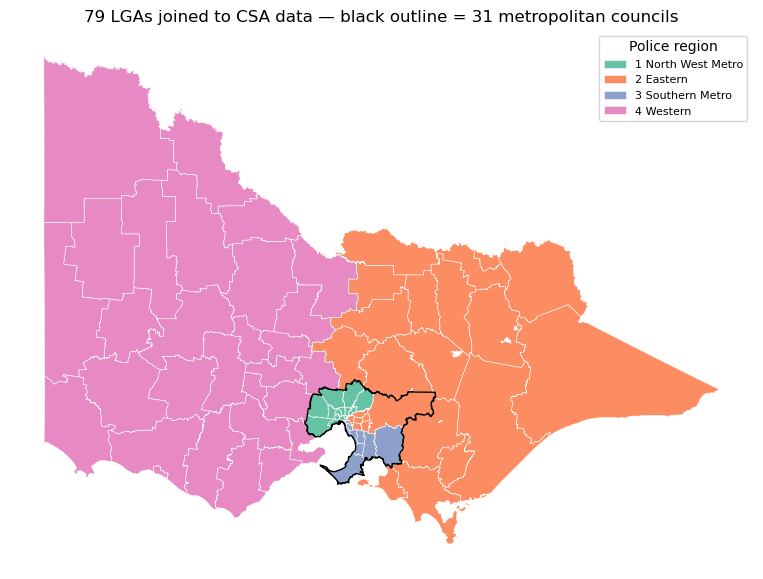

In [12]:
fig, ax = plt.subplots(figsize=(11, 7))
lga_geo.plot(ax=ax, column='police_region', categorical=True, cmap='Set2', edgecolor='white', linewidth=0.4,
             legend=True, legend_kwds={'loc': 'upper right', 'title': 'Police region', 'fontsize': 8})
lga_geo[lga_geo['area_type'] == 'Metropolitan'].dissolve().boundary.plot(ax=ax, color='black', linewidth=1)
ax.set_title('79 LGAs joined to CSA data — black outline = 31 metropolitan councils')
ax.set_axis_off()
plt.show()


## 7. Save processed files

Parquet keeps dtypes and loads in well under a second (vs ~1 min from Excel).

In [13]:
processed = {
    'lga_lookup': lga_lookup,
    'lga_population': lga_population,
    'lga_totals': lga_totals,
    'region_totals': region_totals,
    'special_areas': special_areas,
    'offences_lga': offences_lga,
    'offences_suburb': offences_suburb,
    'location_lga': location_lga,
    'investigation_lga': investigation_lga,
    'drug_type_lga': drug_type_lga,
    'incidents_lga': incidents_lga,
    'state_incidents_rate': state_rate,
    'state_incidents_location': state_location,
    'state_incidents_family': state_family,
    'state_incidents_charge': state_charge,
}
for name, df in processed.items():
    df.to_parquet(OUT / f'{name}.parquet', index=False)
lga_geo.to_file(OUT / 'lga_boundaries.gpkg', driver='GPKG')

pd.DataFrame([{'file': f.name, 'MB': round(f.stat().st_size / 1e6, 2),
               'rows': len(processed[f.stem]) if f.stem in processed else len(lga_geo)}
              for f in sorted(OUT.iterdir()) if f.suffix in {'.parquet', '.gpkg'}])


,file,MB,rows
0,drug_type_lga.parquet,0.05,14985
1,incidents_lga.parquet,0.80,50170
2,investigation_lga.parquet,0.02,3160
3,lga_boundaries.gpkg,8.20,79
4,lga_lookup.parquet,0.01,79
5,lga_population.parquet,0.01,790
6,lga_totals.parquet,0.02,790
7,location_lga.parquet,0.14,55838
8,offences_lga.parquet,0.87,52809
9,offences_suburb.parquet,1.59,371541
